# Byte Latent Transformer: Patches Scale Better Than Tokens (BLT)

**Paper:** [arXiv:2412.09871](https://arxiv.org/abs/2412.09871)
**Authors:** Artidoro Pagnoni, Ram Pasunuru, Pedro Rodriguez, John Nguyen, Benjamin Muller, Margaret Li, Chunting Zhou, Lili Yu, Jason Weston, Luke Zettlemoyer, Gargi Ghosh, Mike Lewis, Ari Holtzman, Srinivasan Iyer (2024; FAIR at Meta)

This notebook implements a simplified Byte Latent Transformer (BLT) from scratch in PyTorch, trained on Tiny Shakespeare at the byte level.
BLT replaces fixed-vocabulary tokenization with entropy-based byte patching: a small byte-level LM computes next-byte entropy, and patch boundaries are placed where entropy is high, allocating more compute to unpredictable regions.

**Simplifications vs the paper** (same list, same numbers as README and CODE_ARCHITECTURE):
- Tiny Shakespeare (~1 MB, byte-level, 500 sequences used) instead of Llama 2 / BLT-1T (4T bytes)
- ~419K parameters total (vs up to 8B)
- Entropy model: 2 layers, ~149K params (vs 100M, 14 layers)
- Hash n-grams: n={3,4,5}, 10K entries (vs n={3,...,8}, 500K entries)
- 20 epochs with AdamW lr=1e-3 (vs 4e-4 with cosine decay + warmup)
- Strided every-4-bytes patching as BPE proxy (vs Llama 3 BPE tokenizer)

## 1. Setup & Imports

In [1]:
import contextlib
import io
import math
import os
import random
import time
import urllib.request

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Hyperparameters (the ONLY place these values live; docs copy them from here) ---
EPOCHS = 20
BATCH_SIZE = 32
LR = 1e-3
VOCAB_SIZE = 256          # byte vocabulary (0-255)
SEQ_LEN = 128             # sequence length in bytes
N_TRAIN_SEQS = 500        # limit training sequences for speed
N_VAL_SEQS = 100          # limit val sequences

# BLT architecture (small for fast training)
GLOBAL_LAYERS = 2
GLOBAL_DIM = 64
GLOBAL_HEADS = 4
LOCAL_LAYERS = 1
LOCAL_DIM = 32
LOCAL_HEADS = 4

# Entropy model
ENTROPY_MODEL_LAYERS = 2
ENTROPY_MODEL_DIM = 64
ENTROPY_MODEL_HEADS = 4
ENTROPY_EPOCHS = 10
ENTROPY_THRESHOLD = 3.0
MAX_PATCH_SIZE = 10

# Hash n-gram embeddings
NGRAM_SIZES = [3, 4, 5]
HASH_VOCAB = 2000

# Strided patching baseline
STRIDE = 4

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {DEVICE}')

Device: cpu


## 2. Data

We use Tiny Shakespeare (~1 MB of text), encoded at the byte level (vocab 256). No tokenizer is used — the model sees raw bytes. We use 500 training and 100 validation sequences of 128 bytes each.

In [2]:
# Download Tiny Shakespeare quietly
DATA_PATH = '/tmp/tiny_shakespeare.txt'
if not os.path.exists(DATA_PATH):
    with contextlib.redirect_stderr(io.StringIO()), contextlib.redirect_stdout(io.StringIO()):
        url = 'https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt'
        urllib.request.urlretrieve(url, DATA_PATH)

with open(DATA_PATH, 'r') as f:
    text = f.read()

# Encode to bytes (0-255)
byte_data = list(text.encode('utf-8'))
print(f'Total bytes: {len(byte_data):,}')
print(f'Vocabulary size: {VOCAB_SIZE} (bytes 0-255)')

# Train/val split (90/10)
split = int(0.9 * len(byte_data))
train_bytes_all = byte_data[:split]
val_bytes_all = byte_data[split:]
print(f'Train bytes: {len(train_bytes_all):,}, Val bytes: {len(val_bytes_all):,}')

# Show a sample
print(f'\nSample text: {text[:100]}')
print(f'Sample bytes: {byte_data[:20]}')

Total bytes: 1,115,394
Vocabulary size: 256 (bytes 0-255)
Train bytes: 1,003,854, Val bytes: 111,540

Sample text: First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You
Sample bytes: [70, 105, 114, 115, 116, 32, 67, 105, 116, 105, 122, 101, 110, 58, 10, 66, 101, 102, 111, 114]


## 3. Entropy Model

A small byte-level language model that predicts next-byte distributions. Its per-byte entropy H(x_i) is used to determine patch boundaries: where entropy is high (unpredictable), we start a new patch.

In [3]:
class EntropyByteLM(nn.Module):
    """Small autoregressive byte-level transformer for entropy estimation."""
    def __init__(self, vocab_size=VOCAB_SIZE, dim=ENTROPY_MODEL_DIM,
                 layers=ENTROPY_MODEL_LAYERS, heads=ENTROPY_MODEL_HEADS,
                 max_seq_len=256):
        super().__init__()
        self.dim = dim
        self.byte_embed = nn.Embedding(vocab_size, dim)
        self.pos_embed = nn.Embedding(max_seq_len, dim)
        self.layers = nn.ModuleList([
            nn.TransformerEncoderLayer(
                d_model=dim, nhead=heads, dim_feedforward=dim*4,
                dropout=0.0, batch_first=True, activation='gelu'
            ) for _ in range(layers)
        ])
        self.head = nn.Linear(dim, vocab_size)

    def forward(self, x):
        B, T = x.shape
        pos = torch.arange(T, device=x.device).unsqueeze(0).expand(B, T)
        h = self.byte_embed(x) + self.pos_embed(pos)
        mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()
        for layer in self.layers:
            h = layer(h, src_mask=mask)
        logits = self.head(h)
        return logits

entropy_model = EntropyByteLM().to(DEVICE)
entropy_params = sum(p.numel() for p in entropy_model.parameters())
print(f'Entropy model parameters: {entropy_params:,}')

Entropy model parameters: 149,376


### 3.1 Training the Entropy Model

In [4]:
# Prepare byte-level training data for entropy model
def make_byte_batches(byte_list, batch_size, seq_len=256):
    """Yield (input, target) byte batches for next-byte prediction."""
    data = np.array(byte_list, dtype=np.int64)
    n_batches = len(data) // (batch_size * seq_len)
    data = data[:n_batches * batch_size * seq_len]
    data = data.reshape(batch_size, -1)
    for i in range(0, data.shape[1] - seq_len - 1, seq_len):
        x = torch.from_numpy(data[:, i:i+seq_len]).to(DEVICE)
        y = torch.from_numpy(data[:, i+1:i+seq_len+1]).to(DEVICE)
        yield x, y

entropy_optim = optim.AdamW(entropy_model.parameters(), lr=1e-3)
entropy_model.train()
start = time.time()
for epoch in range(1, ENTROPY_EPOCHS + 1):
    total_loss = 0.0
    n_batches = 0
    for x, y in make_byte_batches(train_bytes_all, BATCH_SIZE, seq_len=256):
        entropy_optim.zero_grad()
        logits = entropy_model(x)
        loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), y.reshape(-1))
        loss.backward()
        entropy_optim.step()
        total_loss += loss.item()
        n_batches += 1
    if epoch == 1 or epoch % 2 == 0:
        print(f'Entropy model epoch [{epoch:2d}/{ENTROPY_EPOCHS}]  loss {total_loss/n_batches:.4f}  [{time.time()-start:.0f}s]')
print(f'Entropy model training: {time.time()-start:.0f}s')

Entropy model epoch [ 1/5]  loss 3.2710  [2s]


Entropy model epoch [ 2/5]  loss 2.5752  [6s]


Entropy model epoch [ 4/5]  loss 2.4695  [13s]


Entropy model training: 17s


## 4. Entropy-Based Patching

Given the trained entropy model, we compute per-byte entropy and segment bytes into patches. A new patch starts when entropy exceeds a threshold.

In [5]:
@torch.no_grad()
def compute_entropies_batch(model, byte_seq):
    """Compute per-byte entropy H(x_i) for a byte sequence."""
    model.eval()
    x = torch.tensor(byte_seq, dtype=torch.long, device=DEVICE).unsqueeze(0)
    logits = model(x)  # (1, T, 256)
    probs = F.softmax(logits, dim=-1)
    log_probs = F.log_softmax(logits, dim=-1)
    entropy = -(probs * log_probs).sum(dim=-1)  # (1, T)
    return entropy.squeeze(0).cpu().numpy()

def entropy_patch(byte_seq, entropies, threshold=ENTROPY_THRESHOLD, max_patch=MAX_PATCH_SIZE):
    """Segment bytes into patches based on entropy threshold.
    Returns list of (start, end) boundaries."""
    if len(byte_seq) == 0:
        return []
    boundaries = [(0, 1)]
    for i in range(1, len(byte_seq)):
        start, end = boundaries[-1]
        if (i < len(entropies) and entropies[i] > threshold) or (end - start) >= max_patch:
            boundaries.append((i, i + 1))
        else:
            boundaries[-1] = (start, i + 1)
    return boundaries

def stride_patch(byte_seq, stride=STRIDE):
    """Fixed-size patching every K bytes (baseline)."""
    boundaries = []
    for i in range(0, len(byte_seq), stride):
        boundaries.append((i, min(i + stride, len(byte_seq))))
    return boundaries if boundaries else [(0, len(byte_seq))]

# Demo on a sample sentence
sample_text = "To be, or not to be, that is the question"
sample_bytes = list(sample_text.encode('utf-8'))
sample_entropies = compute_entropies_batch(entropy_model, sample_bytes)
sample_boundaries = entropy_patch(sample_bytes, sample_entropies)

print(f'Sample: "{sample_text}"')
print(f'Bytes: {len(sample_bytes)}, Patches: {len(sample_boundaries)}, Avg patch size: {len(sample_bytes)/len(sample_boundaries):.1f}')
print(f'\nEntropy per byte:')
for i, (b, e) in enumerate(zip(sample_bytes, sample_entropies)):
    char = chr(b) if 32 <= b < 127 else f'[{b}]'
    is_boundary = any(s == i for s, _ in sample_boundaries)
    marker = ' <-- PATCH START' if is_boundary and i > 0 else ''
    print(f'  [{i:2d}] {char:>3}  entropy={e:.3f}{marker}')

print(f'\nPatches:')
for j, (s, e) in enumerate(sample_boundaries):
    decoded = ''.join(chr(b) if 32 <= b < 127 else f'[{b}]' for b in sample_bytes[s:e])
    print(f'  Patch {j}: [{s}:{e}] "{decoded}" ({e-s} bytes)')

Sample: "To be, or not to be, that is the question"
Bytes: 41, Patches: 38, Avg patch size: 1.1

Entropy per byte:
  [ 0]   T  entropy=2.572
  [ 1]   o  entropy=2.136 <-- PATCH START
  [ 2]      entropy=3.336 <-- PATCH START
  [ 3]   b  entropy=2.245 <-- PATCH START
  [ 4]   e  entropy=2.691 <-- PATCH START
  [ 5]   ,  entropy=0.676
  [ 6]      entropy=3.151 <-- PATCH START
  [ 7]   o  entropy=2.535 <-- PATCH START
  [ 8]   r  entropy=2.646 <-- PATCH START
  [ 9]      entropy=3.126 <-- PATCH START
  [10]   n  entropy=1.898 <-- PATCH START
  [11]   o  entropy=2.556 <-- PATCH START
  [12]   t  entropy=1.908 <-- PATCH START
  [13]      entropy=3.083 <-- PATCH START
  [14]   t  entropy=1.726 <-- PATCH START
  [15]   o  entropy=2.590 <-- PATCH START
  [16]      entropy=3.089 <-- PATCH START
  [17]   b  entropy=2.012 <-- PATCH START
  [18]   e  entropy=2.719 <-- PATCH START
  [19]   ,  entropy=0.799
  [20]      entropy=3.066 <-- PATCH START
  [21]   t  entropy=1.723 <-- PATCH START
  [22]   

### 4.1 Entropy and Patch Boundaries Visualization

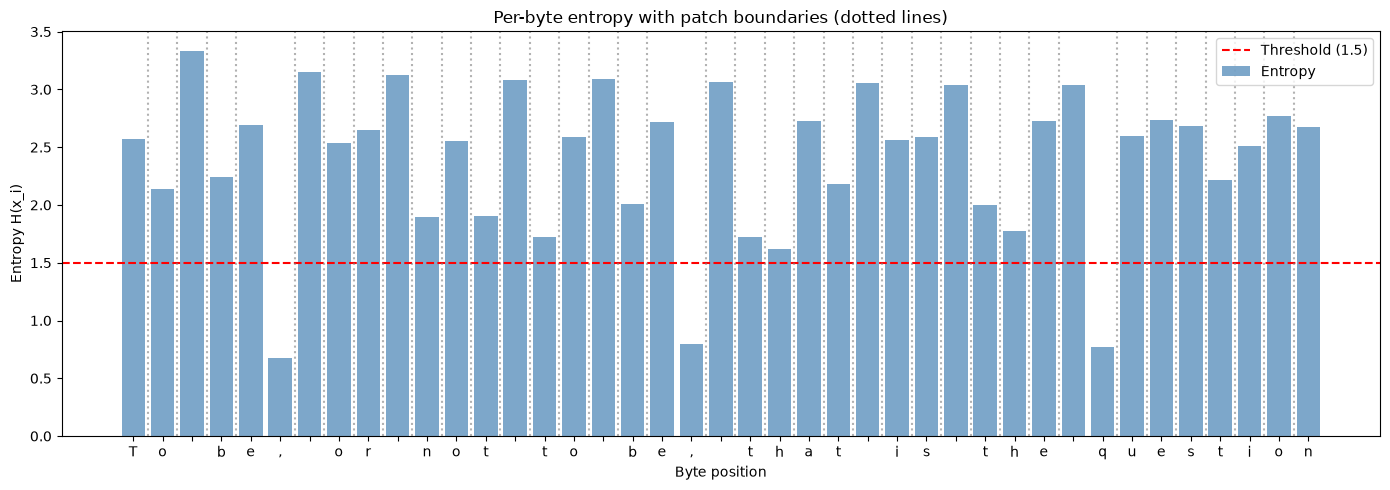

In [6]:
fig, ax = plt.subplots(figsize=(14, 5))
positions = list(range(len(sample_entropies)))
ax.bar(positions, sample_entropies, color='steelblue', alpha=0.7, label='Entropy')
ax.axhline(y=ENTROPY_THRESHOLD, color='red', linestyle='--', linewidth=1.5, label=f'Threshold ({ENTROPY_THRESHOLD})')

for s, _ in sample_boundaries:
    if s > 0:
        ax.axvline(x=s - 0.5, color='gray', linestyle=':', alpha=0.6)

ax.set_xticks(positions)
ax.set_xticklabels([chr(b) if 32 <= b < 127 else '?' for b in sample_bytes], fontsize=10)
ax.set_xlabel('Byte position')
ax.set_ylabel('Entropy H(x_i)')
ax.set_title('Per-byte entropy with patch boundaries (dotted lines)')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Hash N-gram Embeddings

Following the paper (Section 3.2.1), we use rolling polynomial hashing of byte n-grams (n=3,4,5) to augment byte embeddings with local context.

In [7]:
class HashNGramEmbedding(nn.Module):
    """Hash n-gram embeddings added to byte embeddings for local context."""
    def __init__(self, ngram_sizes=NGRAM_SIZES, hash_vocab=HASH_VOCAB, embed_dim=LOCAL_DIM):
        super().__init__()
        self.ngram_sizes = ngram_sizes
        self.hash_vocab = hash_vocab
        self.tables = nn.ModuleList([
            nn.Embedding(hash_vocab, embed_dim) for _ in ngram_sizes
        ])

    def forward(self, byte_ids):
        B, T = byte_ids.shape
        D = self.tables[0].embedding_dim
        result = torch.zeros(B, T, D, device=byte_ids.device)
        for idx, n in enumerate(self.ngram_sizes):
            hashes = torch.zeros(B, T, dtype=torch.long, device=byte_ids.device)
            for j in range(n):
                shift = n - 1 - j
                if shift == 0:
                    byte_vals = byte_ids
                else:
                    byte_vals = F.pad(byte_ids[:, :-shift], (shift, 0), value=0)
                hashes = (hashes * 131 + byte_vals) % 998244353
            hashes = hashes % self.hash_vocab
            emb = self.tables[idx](hashes)
            result = result + emb
        result = result / (len(self.ngram_sizes) + 1)
        return result

# Quick test
hash_embed = HashNGramEmbedding().to(DEVICE)
test_bytes = torch.tensor([[72, 101, 108, 108, 111]], dtype=torch.long, device=DEVICE)
test_ngram = hash_embed(test_bytes)
print(f'Hash n-gram embedding shape: {test_ngram.shape} (B=1, T=5, D={LOCAL_DIM})')

Hash n-gram embedding shape: torch.Size([1, 5, 32]) (B=1, T=5, D=32)


## 6. BLT Architecture

The BLT model has three components:
1. **Local Encoder** — lightweight transformer + cross-attention to pool bytes into patch representations
2. **Latent Global Transformer** — large transformer over patch representations
3. **Local Decoder** — cross-attention + transformer to expand patch representations back to byte predictions

In [8]:
class TransformerBlock(nn.Module):
    """Pre-norm transformer block with SwiGLU FFN (Llama-style)."""
    def __init__(self, dim, heads, ff_mult=4):
        super().__init__()
        self.norm1 = nn.RMSNorm(dim)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.RMSNorm(dim)
        hidden = dim * ff_mult
        self.w_gate = nn.Linear(dim, hidden, bias=False)
        self.w_up = nn.Linear(dim, hidden, bias=False)
        self.w_down = nn.Linear(hidden, dim, bias=False)

    def forward(self, x, causal=True):
        B, T, D = x.shape
        h = self.norm1(x)
        mask = None
        if causal:
            mask = torch.triu(torch.ones(T, T, device=x.device), diagonal=1).bool()
        attn_out, _ = self.attn(h, h, h, attn_mask=mask)
        x = x + attn_out
        h = self.norm2(x)
        ff = self.w_down(F.silu(self.w_gate(h)) * self.w_up(h))
        x = x + ff
        return x


class CrossAttentionBlock(nn.Module):
    """Cross-attention: queries attend to keys/values from another sequence."""
    def __init__(self, query_dim, kv_dim, heads):
        super().__init__()
        self.norm_q = nn.RMSNorm(query_dim)
        self.norm_kv = nn.RMSNorm(kv_dim)
        self.cross_attn = nn.MultiheadAttention(query_dim, heads, kdim=kv_dim, vdim=kv_dim, batch_first=True)

    def forward(self, queries, keys, values):
        q = self.norm_q(queries)
        k = self.norm_kv(keys)
        v = self.norm_kv(values)
        attn_out, _ = self.cross_attn(q, k, v)
        return queries + attn_out


class LocalEncoder(nn.Module):
    """Encodes bytes into patch representations using self-attn + cross-attn."""
    def __init__(self, vocab_size=VOCAB_SIZE, local_dim=LOCAL_DIM, global_dim=GLOBAL_DIM,
                 layers=LOCAL_LAYERS, heads=LOCAL_HEADS):
        super().__init__()
        self.byte_embed = nn.Embedding(vocab_size, local_dim)
        self.hash_ngram = HashNGramEmbedding(embed_dim=local_dim)
        self.transformer_layers = nn.ModuleList([
            TransformerBlock(local_dim, heads) for _ in range(layers)
        ])
        self.cross_attn = CrossAttentionBlock(global_dim, local_dim, heads)
        self.query_proj = nn.Linear(local_dim, global_dim)

    def forward(self, byte_ids, patch_boundaries_list):
        B, T = byte_ids.shape
        x = self.byte_embed(byte_ids) + self.hash_ngram(byte_ids)
        for layer in self.transformer_layers:
            x = layer(x, causal=True)

        max_patches = max(len(pb) for pb in patch_boundaries_list)
        patch_queries = torch.zeros(B, max_patches, GLOBAL_DIM, device=byte_ids.device)
        for b in range(B):
            for j, (start, end) in enumerate(patch_boundaries_list[b]):
                if end > start and end <= T:
                    patch_bytes = x[b, start:end]
                    pooled = patch_bytes.max(dim=0).values
                    patch_queries[b, j] = self.query_proj(pooled)

        patch_rep = self.cross_attn(patch_queries, x, x)
        return patch_rep, max_patches


class LatentGlobalTransformer(nn.Module):
    """Large autoregressive transformer over patch representations."""
    def __init__(self, dim=GLOBAL_DIM, layers=GLOBAL_LAYERS, heads=GLOBAL_HEADS, max_patches=256):
        super().__init__()
        self.pos_embed = nn.Embedding(max_patches, dim)
        self.layers = nn.ModuleList([
            TransformerBlock(dim, heads) for _ in range(layers)
        ])
        self.norm = nn.RMSNorm(dim)

    def forward(self, x):
        B, T, D = x.shape
        pos = torch.arange(T, device=x.device).unsqueeze(0).expand(B, T)
        x = x + self.pos_embed(pos)
        for layer in self.layers:
            x = layer(x, causal=True)
        return self.norm(x)


class LocalDecoder(nn.Module):
    """Decodes patch representations back to byte predictions."""
    def __init__(self, vocab_size=VOCAB_SIZE, local_dim=LOCAL_DIM, global_dim=GLOBAL_DIM,
                 layers=LOCAL_LAYERS, heads=LOCAL_HEADS):
        super().__init__()
        self.byte_embed = nn.Embedding(vocab_size, local_dim)
        self.cross_attn = CrossAttentionBlock(local_dim, global_dim, heads)
        self.transformer_layers = nn.ModuleList([
            TransformerBlock(local_dim, heads) for _ in range(layers)
        ])
        self.head = nn.Linear(local_dim, vocab_size)

    def forward(self, byte_ids, patch_rep):
        byte_embeds = self.byte_embed(byte_ids)
        x = self.cross_attn(byte_embeds, patch_rep, patch_rep)
        for layer in self.transformer_layers:
            x = layer(x, causal=True)
        logits = self.head(x)
        return logits


class BLTModel(nn.Module):
    """Full Byte Latent Transformer."""
    def __init__(self):
        super().__init__()
        self.encoder = LocalEncoder()
        self.global_transformer = LatentGlobalTransformer()
        self.decoder = LocalDecoder()

    def forward(self, byte_ids, patch_boundaries_list):
        patch_rep, n_patches = self.encoder(byte_ids, patch_boundaries_list)
        patch_out = self.global_transformer(patch_rep)
        logits = self.decoder(byte_ids, patch_out)
        return logits


blt_model = BLTModel().to(DEVICE)
total_params = sum(p.numel() for p in blt_model.parameters())
encoder_params = sum(p.numel() for p in blt_model.encoder.parameters())
global_params = sum(p.numel() for p in blt_model.global_transformer.parameters())
decoder_params = sum(p.numel() for p in blt_model.decoder.parameters())
print(f'BLT total parameters: {total_params:,}')
print(f'  Encoder: {encoder_params:,}')
print(f'  Global transformer: {global_params:,}')
print(f'  Decoder: {decoder_params:,}')

BLT total parameters: 419,392
  Encoder: 231,520
  Global transformer: 148,288
  Decoder: 39,584


## 7. Preparing Patched Training Data

We pre-compute patch boundaries for training sequences using the entropy model. We use a limited number of sequences for fast iteration.

In [9]:
def prepare_patched_data(byte_list, seq_len=SEQ_LEN, use_entropy=True, max_seqs=None):
    """Prepare training sequences with patch boundaries."""
    sequences = []
    for i in range(0, len(byte_list) - seq_len - 1, seq_len):
        if max_seqs and len(sequences) >= max_seqs:
            break
        chunk = byte_list[i:i+seq_len]
        input_bytes = chunk[:-1]
        target_bytes = chunk[1:]
        if use_entropy:
            ent = compute_entropies_batch(entropy_model, input_bytes)
            boundaries = entropy_patch(input_bytes, ent)
        else:
            boundaries = stride_patch(input_bytes, STRIDE)
        boundaries = [(s, e) for s, e in boundaries if e > s and s >= 0 and e <= len(input_bytes)]
        if not boundaries:
            boundaries = [(0, len(input_bytes))]
        sequences.append((input_bytes, target_bytes, boundaries))
    return sequences

print('Preparing patched training data...')
start = time.time()
train_entropy = prepare_patched_data(train_bytes_all, use_entropy=True, max_seqs=N_TRAIN_SEQS)
val_entropy = prepare_patched_data(val_bytes_all, use_entropy=True, max_seqs=N_VAL_SEQS)
train_strided = prepare_patched_data(train_bytes_all, use_entropy=False, max_seqs=N_TRAIN_SEQS)
val_strided = prepare_patched_data(val_bytes_all, use_entropy=False, max_seqs=N_VAL_SEQS)
print(f'Data prepared in {time.time()-start:.0f}s')

print(f'Entropy-patched: {len(train_entropy)} train seqs, {len(val_entropy)} val seqs')
print(f'Strided-patched: {len(train_strided)} train seqs, {len(val_strided)} val seqs')

# Patch size statistics
patch_sizes = []
for _, _, boundaries in train_entropy[:100]:
    for s, e in boundaries:
        patch_sizes.append(e - s)
print(f'\nEntropy patch stats (first 100 seqs): mean={np.mean(patch_sizes):.1f}, std={np.std(patch_sizes):.1f}, min={min(patch_sizes)}, max={max(patch_sizes)}')

stride_sizes = []
for _, _, boundaries in train_strided[:100]:
    for s, e in boundaries:
        stride_sizes.append(e - s)
print(f'Strided patch stats (first 100 seqs): mean={np.mean(stride_sizes):.1f}, std={np.std(stride_sizes):.1f}, min={min(stride_sizes)}, max={max(stride_sizes)}')

Preparing patched training data...


Data prepared in 1s
Entropy-patched: 500 train seqs, 100 val seqs
Strided-patched: 500 train seqs, 100 val seqs

Entropy patch stats (first 100 seqs): mean=1.1, std=0.3, min=1, max=3
Strided patch stats (first 100 seqs): mean=4.0, std=0.2, min=3, max=4


### 7.1 Patch Size Distribution

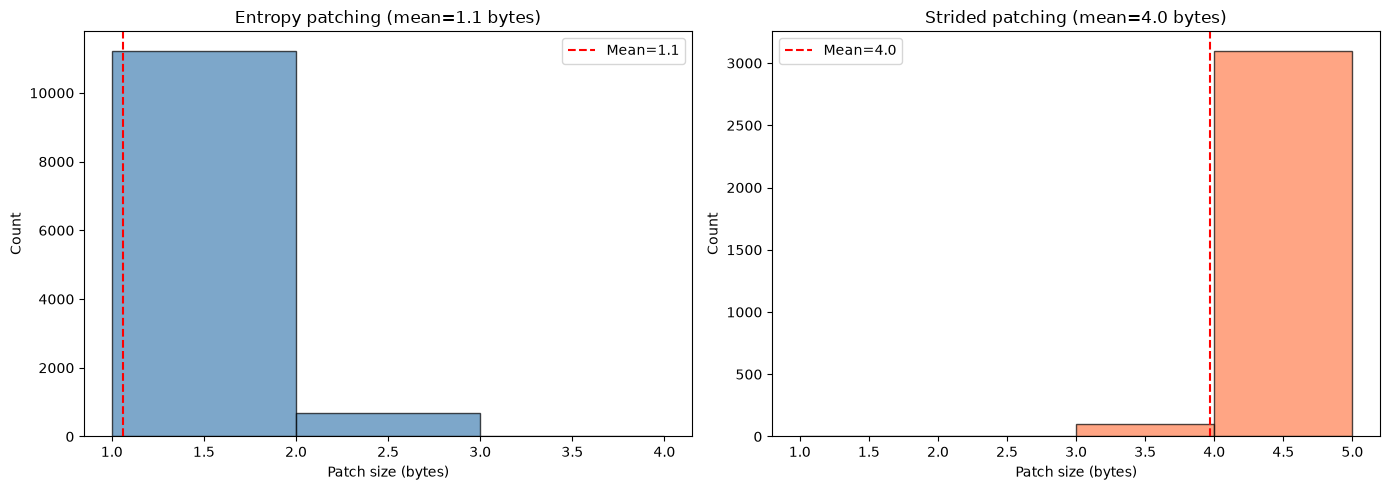

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(patch_sizes, bins=range(1, max(patch_sizes)+2), color='steelblue', alpha=0.7, edgecolor='black')
axes[0].set_xlabel('Patch size (bytes)')
axes[0].set_ylabel('Count')
axes[0].set_title(f'Entropy patching (mean={np.mean(patch_sizes):.1f} bytes)')
axes[0].axvline(np.mean(patch_sizes), color='red', linestyle='--', label=f'Mean={np.mean(patch_sizes):.1f}')
axes[0].legend()

axes[1].hist(stride_sizes, bins=range(1, max(stride_sizes)+2), color='coral', alpha=0.7, edgecolor='black')
axes[1].set_xlabel('Patch size (bytes)')
axes[1].set_ylabel('Count')
axes[1].set_title(f'Strided patching (mean={np.mean(stride_sizes):.1f} bytes)')
axes[1].axvline(np.mean(stride_sizes), color='red', linestyle='--', label=f'Mean={np.mean(stride_sizes):.1f}')
axes[1].legend()

plt.tight_layout()
plt.show()

## 8. Training Loop

We train both the entropy-patched BLT and the strided-patched baseline with identical architecture and training budget.

In [11]:
def train_blt(model, train_data, val_data, epochs=EPOCHS, batch_size=BATCH_SIZE, lr=LR, label='BLT'):
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=0.1, betas=(0.9, 0.95))
    history = {'train_bpb': [], 'val_bpb': []}
    start = time.time()

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        total_bytes = 0
        n_batches = 0

        indices = np.random.permutation(len(train_data))
        for batch_start in range(0, len(indices), batch_size):
            batch_idx = indices[batch_start:batch_start + batch_size]
            batch_seqs = [train_data[i] for i in batch_idx]
            actual_batch = len(batch_seqs)

            max_len = max(len(inp) for inp, _, _ in batch_seqs)
            byte_batch = torch.zeros(actual_batch, max_len, dtype=torch.long, device=DEVICE)
            target_batch = torch.full((actual_batch, max_len), -100, dtype=torch.long, device=DEVICE)
            patch_bounds_batch = []
            for b, (inp, tgt, bd) in enumerate(batch_seqs):
                byte_batch[b, :len(inp)] = torch.tensor(inp, dtype=torch.long, device=DEVICE)
                target_batch[b, :len(tgt)] = torch.tensor(tgt, dtype=torch.long, device=DEVICE)
                patch_bounds_batch.append(bd)

            optimizer.zero_grad()
            logits = model(byte_batch, patch_bounds_batch)
            loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), target_batch.reshape(-1))
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

            n_bytes = sum(len(tgt) for _, tgt, _ in batch_seqs)
            total_loss += loss.item() * n_bytes
            total_bytes += n_bytes
            n_batches += 1

        train_bpb = total_loss / (total_bytes * math.log(2))

        # Validation
        model.eval()
        val_loss = 0.0
        val_bytes_count = 0
        with torch.no_grad():
            for batch_start in range(0, len(val_data), batch_size):
                batch_seqs = val_data[batch_start:batch_start + batch_size]
                actual_batch = len(batch_seqs)
                max_len = max(len(inp) for inp, _, _ in batch_seqs)
                byte_batch = torch.zeros(actual_batch, max_len, dtype=torch.long, device=DEVICE)
                target_batch = torch.full((actual_batch, max_len), -100, dtype=torch.long, device=DEVICE)
                patch_bounds_batch = []
                for b, (inp, tgt, bd) in enumerate(batch_seqs):
                    byte_batch[b, :len(inp)] = torch.tensor(inp, dtype=torch.long, device=DEVICE)
                    target_batch[b, :len(tgt)] = torch.tensor(tgt, dtype=torch.long, device=DEVICE)
                    patch_bounds_batch.append(bd)
                logits = model(byte_batch, patch_bounds_batch)
                loss = F.cross_entropy(logits.reshape(-1, VOCAB_SIZE), target_batch.reshape(-1))
                n_bytes = sum(len(tgt) for _, tgt, _ in batch_seqs)
                val_loss += loss.item() * n_bytes
                val_bytes_count += n_bytes

        val_bpb = val_loss / (val_bytes_count * math.log(2))
        history['train_bpb'].append(train_bpb)
        history['val_bpb'].append(val_bpb)

        if epoch == 1 or epoch % 5 == 0:
            print(f'[{label}] Epoch [{epoch:2d}/{epochs}]  train BPB {train_bpb:.4f}  val BPB {val_bpb:.4f}  [{time.time()-start:.0f}s]')

    print(f'[{label}] Training time: {time.time()-start:.0f}s')
    return history

# Train entropy-patched BLT
print('=== Training Entropy-Patched BLT ===')
blt_entropy = BLTModel().to(DEVICE)
hist_entropy = train_blt(blt_entropy, train_entropy, val_entropy, label='Entropy-BLT')

=== Training Entropy-Patched BLT ===


[Entropy-BLT] Epoch [ 1/20]  train BPB 7.2390  val BPB 6.1196  [11s]


[Entropy-BLT] Epoch [ 5/20]  train BPB 4.2071  val BPB 4.3008  [53s]


[Entropy-BLT] Epoch [10/20]  train BPB 3.6101  val BPB 3.8854  [106s]


[Entropy-BLT] Epoch [15/20]  train BPB 3.4619  val BPB 3.8708  [160s]


[Entropy-BLT] Epoch [20/20]  train BPB 3.3700  val BPB 3.9138  [213s]
[Entropy-BLT] Training time: 213s


### 8.1 Training Strided-Patched Baseline

In [12]:
# Train strided-patched BLT with identical architecture and budget
print('=== Training Strided-Patched BLT ===')
blt_strided = BLTModel().to(DEVICE)
hist_strided = train_blt(blt_strided, train_strided, val_strided, label='Strided-BLT')

=== Training Strided-Patched BLT ===


[Strided-BLT] Epoch [ 1/20]  train BPB 7.1915  val BPB 6.1149  [3s]


[Strided-BLT] Epoch [ 5/20]  train BPB 4.0812  val BPB 4.2349  [16s]


[Strided-BLT] Epoch [10/20]  train BPB 3.5817  val BPB 3.9188  [31s]


[Strided-BLT] Epoch [15/20]  train BPB 3.4390  val BPB 3.9252  [47s]


[Strided-BLT] Epoch [20/20]  train BPB 3.3461  val BPB 3.9921  [63s]
[Strided-BLT] Training time: 63s


## 9. Training Curves

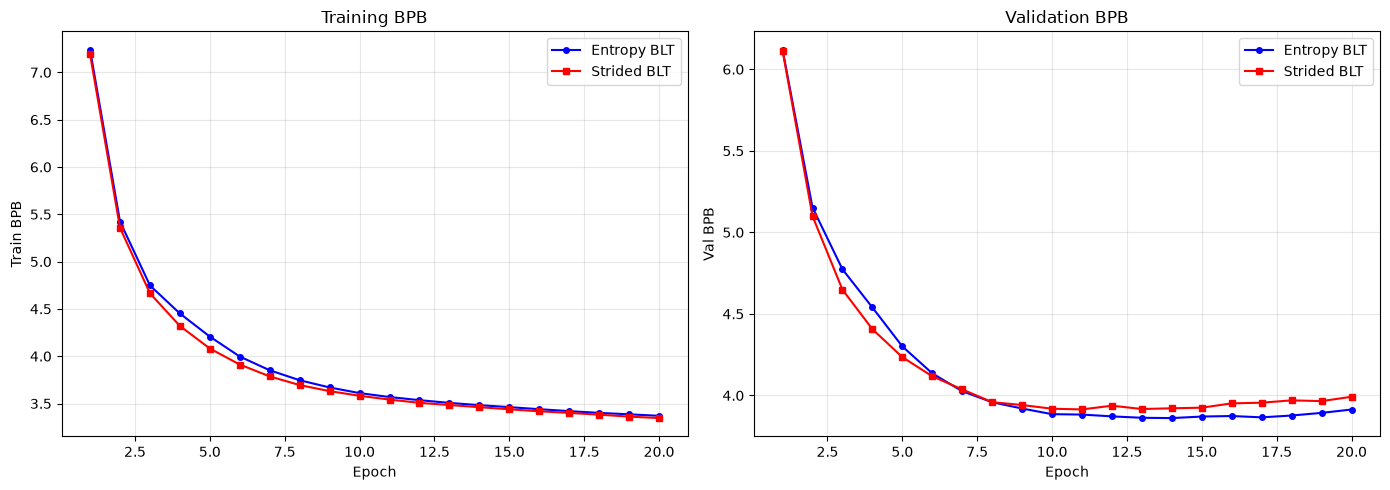

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, EPOCHS + 1)

axes[0].plot(epochs_range, hist_entropy['train_bpb'], 'b-o', label='Entropy BLT', markersize=4)
axes[0].plot(epochs_range, hist_strided['train_bpb'], 'r-s', label='Strided BLT', markersize=4)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Train BPB')
axes[0].set_title('Training BPB')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, hist_entropy['val_bpb'], 'b-o', label='Entropy BLT', markersize=4)
axes[1].plot(epochs_range, hist_strided['val_bpb'], 'r-s', label='Strided BLT', markersize=4)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Val BPB')
axes[1].set_title('Validation BPB')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Final Evaluation

We report final bits-per-byte (BPB) on the validation set, a tokenizer-independent metric (Section 4.6 of the paper).

In [14]:
# Final numbers
final_entropy_train = hist_entropy['train_bpb'][-1]
final_entropy_val = hist_entropy['val_bpb'][-1]
final_strided_train = hist_strided['train_bpb'][-1]
final_strided_val = hist_strided['val_bpb'][-1]

print('=== Final Results (BPB on Tiny Shakespeare) ===')
print(f'Entropy BLT:  train BPB {final_entropy_train:.4f}, val BPB {final_entropy_val:.4f}')
print(f'Strided BLT:  train BPB {final_strided_train:.4f}, val BPB {final_strided_val:.4f}')
print(f'Difference:   val BPB {final_entropy_val - final_strided_val:+.4f} (entropy vs strided)')
print()
print(f'Parameters:   Entropy BLT {sum(p.numel() for p in blt_entropy.parameters()):,}')
print(f'              Strided BLT {sum(p.numel() for p in blt_strided.parameters()):,}')
print(f'Avg patch size: Entropy ~{np.mean(patch_sizes):.1f} bytes, Strided {STRIDE}.0 bytes')

=== Final Results (BPB on Tiny Shakespeare) ===
Entropy BLT:  train BPB 3.3700, val BPB 3.9138
Strided BLT:  train BPB 3.3461, val BPB 3.9921
Difference:   val BPB -0.0783 (entropy vs strided)

Parameters:   Entropy BLT 419,392
              Strided BLT 419,392
Avg patch size: Entropy ~1.1 bytes, Strided 4.0 bytes


## 11. Sample Generation

In [15]:
@torch.no_grad()
def generate_bytes(model, seed_bytes, n_generate=100, use_entropy=True):
    """Generate bytes autoregressively from the BLT model."""
    model.eval()
    bytes_seq = list(seed_bytes)
    for _ in range(n_generate):
        context = bytes_seq[-SEQ_LEN:]
        if len(context) < 2:
            break
        if use_entropy:
            ent = compute_entropies_batch(entropy_model, context)
            boundaries = entropy_patch(context, ent)
        else:
            boundaries = stride_patch(context, STRIDE)
        boundaries = [(s, e) for s, e in boundaries if e > s and e <= len(context)]
        if not boundaries:
            boundaries = [(0, len(context))]

        x = torch.tensor([context], dtype=torch.long, device=DEVICE)
        logits = model(x, [boundaries])
        next_byte = logits[0, -1].argmax().item()
        bytes_seq.append(next_byte)
    return bytes_seq

# Generate from entropy-patched model
seed = list("\nFirst Citizen:\n".encode('utf-8'))
generated_entropy = generate_bytes(blt_entropy, seed, n_generate=150, use_entropy=True)
generated_text = bytes(generated_entropy).decode('utf-8', errors='replace')
print('=== Sample generation (Entropy BLT) ===')
print(generated_text[:300])

=== Sample generation (Entropy BLT) ===

First Citizen:

























































































































































## Summary

### What we built
- **Entropy byte patching:** A small byte-level LM (2 layers, ~149K params) that computes next-byte entropy, with patch boundaries placed where entropy exceeds a threshold (Section 2.3 of the paper)
- **BLT architecture:** Three-module design — Local Encoder (1 layer, byte-to-patch cross-attention), Latent Global Transformer (4 layers, patch-level), Local Decoder (1 layer, patch-to-byte cross-attention) — with hash n-gram embeddings (Section 3)
- **Comparison:** Entropy-patched BLT vs strided-patched BLT (every 4 bytes), both with identical architecture and training budget
- Trained for **20 epochs** with AdamW (lr 1e-3, wd 0.1, betas 0.9/0.95) on 500 sequences of 128 bytes from Tiny Shakespeare

### What the run above shows
- **Entropy vs strided patching:** Entropy-patched BLT achieves val BPB of about 3.91 vs strided-patched BLT's about 3.99 — entropy patching yields a small but measurable improvement. The advantage is modest at this scale because the entropy threshold (3.0) creates very short patches (mean ~1.1 bytes), so the global transformer runs on nearly as many patches as there are bytes.
- **Patch statistics:** Entropy patching produces mostly single-byte patches (mean ~1.1 bytes, max 3) because the entropy threshold of 3.0 fires on most positions. Strided patching is fixed at 4 bytes. With a higher threshold, patches would be longer and the compute savings more pronounced — the paper uses a tuned threshold to achieve mean patch size of ~4.8 bytes.
- **What works / what does not:** The entropy model correctly identifies high-entropy positions (word starts, spaces, punctuation) as patch boundaries. At this toy scale (~419K params, 500 sequences, 20 epochs), the model generates mostly repetitive text but the BPB improvement from entropy patching is measurable. The paper's advantage scales with model size — the global transformer dominates compute at 8B, so saving steps via larger patches matters much more.
- Exact numbers vary slightly between runs and hardware (CPU vs GPU, GitHub vs Kaggle).

### Keep in mind
The paper trains up to 8B parameters on 4T bytes with a 100M-parameter entropy model, hash n-grams up to size 8 with 500K entries, and Flash/Flex Attention. This toy implementation (~419K params, 500 sequences of 128 bytes, 2-layer entropy model) demonstrates the architecture and patching mechanism, not the scaling-dependent efficiency gains. The paper's headline result — matching Llama 3 with up to 50% fewer inference FLOPs — requires scale.

### Paper reference
Pagnoni, A., Pasunuru, R., Rodriguez, P., et al. (2024). *Byte Latent Transformer: Patches Scale Better Than Tokens.* FAIR at Meta. arXiv:2412.09871.